# Module 24 — Manual Transformer Implementation

**Goal:** build a small encoder-decoder Transformer manually, then train it and perform autoregressive generation.

### Flow

1. Token embeddings
2. Positional encoding
3. Multi-head attention
4. Feed-forward network
5. Residual connections + LayerNorm
6. Encoder
7. Masking
   - padding mask
   - causal mask
   - target self-attention mask
   - encoder-decoder cross-attention mask
8. Decoder
9. Complete Transformer
10. Tiny seq2seq dataset
11. Teacher-forcing training
12. Validation + token accuracy
13. Autoregressive greedy decoding
14. Sequence-level evaluation
15. PyTorch framework comparison

> **Important:** We are implementing the Transformer architecture manually. We will use PyTorch tensors, `nn.Module`, `nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `CrossEntropyLoss`, and the optimizer, but we will **not** use `nn.Transformer` for the main model.


## 1. Setup and Token Embedding

In [1]:
import math
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Small values for experimentation.
vocab_size = 100
d_model = 128
num_heads = 8
d_ff = 256
num_encoder_layers = 2
num_decoder_layers = 2
max_seq_len = 16

PAD_ID = 0
SOS_ID = 1
EOS_ID = 2

embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)

tokens = torch.tensor([
    [12, 45, 78, PAD_ID],
    [33, 17, 29, 91]
])

x = embedding(tokens)

print("Tokens shape   :", tokens.shape)
print("Embedding shape:", x.shape)


Device: cuda
Tokens shape   : torch.Size([2, 4])
Embedding shape: torch.Size([2, 4, 128])


## 2. Positional Encoding

Self-attention does not inherently know token order, so we add positional information.

For position $pos$ and dimension index $i$:

$$
PE_{pos, 2i}
=
\sin\left(
\frac{pos}{10000^{\frac{2i}{d_{model}}}}
\right)
$$

$$
PE_{pos, 2i+1}
=
\cos\left(
\frac{pos}{10000^{\frac{2i}{d_{model}}}}
\right)
$$

Where:

- $pos$ = position of the token in the sequence
- $i$ = dimension index
- $d_{model}$ = embedding dimension
- Even dimensions ($2i$) use **sine**
- Odd dimensions ($2i+1$) use **cosine**

In [2]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_seq_len):
        super().__init__()

        position = torch.arange(max_seq_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # Buffer moves with the model but is not trainable.
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        seq_len = x.size(1)
        return x + self.pe[:, :seq_len, :]


pos_encoding = PositionalEncoding(d_model, max_seq_len)

x_with_position = pos_encoding(x)

print("Input shape :", x.shape)
print("Output shape:", x_with_position.shape)


Input shape : torch.Size([2, 4, 128])
Output shape: torch.Size([2, 4, 128])


## 3. Multi-Head Attention

We implement scaled dot-product attention manually:

$$
Attention(Q,K,V)
=
softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

The same module supports:

- self-attention: `key_value=None`
- cross-attention: `key_value=encoder_output`

In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x, key_value=None, mask=None):
        batch_size, query_len, _ = x.shape

        # Q always comes from x.
        Q = self.W_q(x)

        # For self-attention K,V come from x.
        # For cross-attention K,V come from encoder_output.
        if key_value is None:
            key_value = x

        K = self.W_k(key_value)
        V = self.W_v(key_value)

        key_len = K.size(1)

        # (B, L, D) -> (B, H, L, head_dim)
        Q = Q.view(
            batch_size, query_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        K = K.view(
            batch_size, key_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size, key_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # (B, H, query_len, head_dim)
        # ×
        # (B, H, head_dim, key_len)
        # =
        # (B, H, query_len, key_len)
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)

        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))

        attention_weights = torch.softmax(scores, dim=-1)

        attention_output = torch.matmul(attention_weights, V)

        # (B, H, L, head_dim) -> (B, L, D)
        attention_output = attention_output.transpose(1, 2)
        attention_output = attention_output.contiguous().view(
            batch_size, query_len, self.d_model
        )

        return self.W_o(attention_output)


mha = MultiHeadAttention(d_model=d_model, num_heads=num_heads)
attention_output = mha(x_with_position)

print("Attention output:", attention_output.shape)


Attention output: torch.Size([2, 4, 128])


## 4. Feed-Forward Network

Each Transformer block applies the same small MLP independently to every sequence position:

$$
[
FFN(x)=W_2\,ReLU(W_1x+b_1)+b_2
]
$$

In [4]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)


ffn = FeedForward(d_model, d_ff)
ffn_output = ffn(attention_output)

print("FFN output:", ffn_output.shape)


FFN output: torch.Size([2, 4, 128])


## 5. Encoder Block

Post-norm formulation used here:
$$
[
x' = LayerNorm(x + SelfAttention(x))
]
$$

$$[
output = LayerNorm(x' + FFN(x'))
]
$$

In [5]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.attention = MultiHeadAttention(d_model, num_heads)
        self.ffn = FeedForward(d_model, d_ff)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        attention_output = self.attention(x, mask=mask)
        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)
        x = self.norm2(x + ffn_output)

        return x


In [6]:
class Encoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff):
        super().__init__()

        self.layers = nn.ModuleList([
            EncoderBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

    def forward(self, x, mask=None):
        for layer in self.layers:
            x = layer(x, mask=mask)

        return x


# 6. Masking

There are three masking ideas we need:

1. **Padding mask** — ignore `<PAD>` tokens.
2. **Causal mask** — stop the decoder from looking into future target positions.
3. **Cross-attention mask** — when the decoder reads encoder outputs, ignore source `<PAD>` positions.

The actual decoder self-attention mask is:

$$
[
TargetPaddingMask \land CausalMask
]
$$

In [7]:
def create_padding_mask(tokens, pad_token_id=PAD_ID):
    # tokens: (B, L)
    # output: (B, 1, 1, L)
    return (tokens != pad_token_id).unsqueeze(1).unsqueeze(2)


def create_causal_mask(seq_len, device=None):
    # output: (1, 1, L, L)
    mask = torch.tril(
        torch.ones(
            seq_len,
            seq_len,
            dtype=torch.bool,
            device=device
        )
    )
    return mask.unsqueeze(0).unsqueeze(1)


def combine_masks(*masks):
    final_mask = masks[0]

    for mask in masks[1:]:
        final_mask = final_mask & mask

    return final_mask


In [8]:
# Test all mask shapes.

src = torch.tensor([
    [12, 45, 78, PAD_ID],
    [33, 17, 29, 91]
], device=device)

tgt = torch.tensor([
    [SOS_ID, 5, 8, EOS_ID],
    [SOS_ID, 7, 3, EOS_ID]
], device=device)

src_padding_mask = create_padding_mask(src)

tgt_padding_mask = create_padding_mask(tgt)

tgt_causal_mask = create_causal_mask(
    tgt.size(1),
    device=tgt.device
)

tgt_self_mask = combine_masks(
    tgt_padding_mask,
    tgt_causal_mask
)

cross_attention_mask = src_padding_mask

print("Source padding :", src_padding_mask.shape)
print("Target padding :", tgt_padding_mask.shape)
print("Causal         :", tgt_causal_mask.shape)
print("Target self    :", tgt_self_mask.shape)
print("Cross-attention:", cross_attention_mask.shape)


Source padding : torch.Size([2, 1, 1, 4])
Target padding : torch.Size([2, 1, 1, 4])
Causal         : torch.Size([1, 1, 4, 4])
Target self    : torch.Size([2, 1, 4, 4])
Cross-attention: torch.Size([2, 1, 1, 4])


### What each mask does

```text
Encoder self-attention:
    source -> source
    use source padding mask

Decoder self-attention:
    target -> target
    use target padding mask + causal mask

Decoder cross-attention:
    target -> encoder output
    use source padding mask
```


## 7. Decoder Block

In [9]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.cross_attention = MultiHeadAttention(d_model, num_heads)
        self.ffn = FeedForward(d_model, d_ff)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(
        self,
        x,
        encoder_output,
        self_mask=None,
        cross_mask=None
    ):
        # 1. Masked decoder self-attention
        self_attention_output = self.self_attention(
            x,
            mask=self_mask
        )
        x = self.norm1(x + self_attention_output)

        # 2. Encoder-decoder cross-attention
        cross_attention_output = self.cross_attention(
            x,
            key_value=encoder_output,
            mask=cross_mask
        )
        x = self.norm2(x + cross_attention_output)

        # 3. Feed-forward network
        ffn_output = self.ffn(x)
        x = self.norm3(x + ffn_output)

        return x


In [10]:
class Decoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff):
        super().__init__()

        self.layers = nn.ModuleList([
            DecoderBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

    def forward(
        self,
        x,
        encoder_output,
        self_mask=None,
        cross_mask=None
    ):
        for layer in self.layers:
            x = layer(
                x,
                encoder_output,
                self_mask=self_mask,
                cross_mask=cross_mask
            )

        return x


## 8. Complete Manual Transformer

Now the masks are actually wired into the architecture.

```text
SOURCE
  ↓
Embedding + Position
  ↓
Encoder
  ↓
Encoder output
  ↓
                         TARGET
                           ↓
                    Embedding + Position
                           ↓
                 Masked Decoder Self-Attention
                           ↓
                  Encoder-Decoder Attention
                           ↓
                         FFN
                           ↓
                      Linear Head
                           ↓
                        Logits
```


In [11]:
class Transformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model,
        num_heads,
        d_ff,
        num_encoder_layers,
        num_decoder_layers,
        max_seq_len
    ):
        super().__init__()

        self.d_model = d_model

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_ID
        )

        self.positional_encoding = PositionalEncoding(
            d_model,
            max_seq_len
        )

        self.encoder = Encoder(
            num_encoder_layers,
            d_model,
            num_heads,
            d_ff
        )

        self.decoder = Decoder(
            num_decoder_layers,
            d_model,
            num_heads,
            d_ff
        )

        self.output_projection = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, src, tgt):
        # -------------------------
        # Masks
        # -------------------------
        src_padding_mask = create_padding_mask(src)

        tgt_padding_mask = create_padding_mask(tgt)

        tgt_causal_mask = create_causal_mask(
            tgt.size(1),
            device=tgt.device
        )

        tgt_self_mask = combine_masks(
            tgt_padding_mask,
            tgt_causal_mask
        )

        cross_attention_mask = src_padding_mask

        # -------------------------
        # Encoder
        # -------------------------
        src_x = self.embedding(src)
        src_x = self.positional_encoding(src_x)

        encoder_output = self.encoder(
            src_x,
            mask=src_padding_mask
        )

        # -------------------------
        # Decoder
        # -------------------------
        tgt_x = self.embedding(tgt)
        tgt_x = self.positional_encoding(tgt_x)

        decoder_output = self.decoder(
            tgt_x,
            encoder_output,
            self_mask=tgt_self_mask,
            cross_mask=cross_attention_mask
        )

        # -------------------------
        # Vocabulary logits
        # -------------------------
        logits = self.output_projection(decoder_output)

        return logits


In [12]:
model = Transformer(
    vocab_size=vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    d_ff=d_ff,
    num_encoder_layers=num_encoder_layers,
    num_decoder_layers=num_decoder_layers,
    max_seq_len=max_seq_len
).to(device)

print(model)


Transformer(
  (embedding): Embedding(100, 128, padding_idx=0)
  (positional_encoding): PositionalEncoding()
  (encoder): Encoder(
    (layers): ModuleList(
      (0-1): 2 x EncoderBlock(
        (attention): MultiHeadAttention(
          (W_q): Linear(in_features=128, out_features=128, bias=True)
          (W_k): Linear(in_features=128, out_features=128, bias=True)
          (W_v): Linear(in_features=128, out_features=128, bias=True)
          (W_o): Linear(in_features=128, out_features=128, bias=True)
        )
        (ffn): FeedForward(
          (network): Sequential(
            (0): Linear(in_features=128, out_features=256, bias=True)
            (1): ReLU()
            (2): Linear(in_features=256, out_features=128, bias=True)
          )
        )
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      )
    )
  )
  (decoder): Decoder(
    (layers): ModuleList(
      (0-1): 2 x DecoderBl

## 9. Forward-Pass Test

In [13]:
src = torch.tensor([
    [12, 45, 78, PAD_ID],
    [33, 17, 29, 91]
], device=device)

tgt = torch.tensor([
    [SOS_ID, 5, 8, EOS_ID],
    [SOS_ID, 7, 3, EOS_ID]
], device=device)

logits = model(src, tgt)

print("Source shape :", src.shape)
print("Target shape :", tgt.shape)
print("Logits shape :", logits.shape)

assert logits.shape == (
    src.size(0),
    tgt.size(1),
    vocab_size
)

print("Forward pass OK.")


Source shape : torch.Size([2, 4])
Target shape : torch.Size([2, 4])
Logits shape : torch.Size([2, 4, 100])
Forward pass OK.


## 10. Parameter Count

In [14]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters    :", total_params)
print("Trainable parameters:", trainable_params)


Total parameters    : 688228
Trainable parameters: 688228


# Part 2 — Tiny Seq2Seq Training Task

Before using a real NLP dataset, we use a **controlled synthetic task**.

### Task

The model receives a sequence of integers and must output the **reversed sequence**.

Example:

```text
Input:  [7, 12, 25]
Target: [25, 12, 7]
```

The model learns the complete encoder-decoder pipeline without introducing tokenizer/dataset complexity at the same time.


In [15]:
# Keep this dataset small so the manual implementation is easy to debug.

DATA_VOCAB_START = 3
DATA_VOCAB_END = 30
MAX_SOURCE_LEN = 5
NUM_SAMPLES = 1000

def generate_example():
    length = random.randint(2, MAX_SOURCE_LEN)
    source = [
        random.randint(DATA_VOCAB_START, DATA_VOCAB_END)
        for _ in range(length)
    ]

    target = list(reversed(source))

    return source, target


examples = [generate_example() for _ in range(NUM_SAMPLES)]

print("Example:")
print("Source:", examples[0][0])
print("Target:", examples[0][1])


Example:
Source: [11, 14]
Target: [14, 11]


In [16]:
class ReverseSeq2SeqDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        source, target = self.examples[idx]
        return torch.tensor(source), torch.tensor(target)


random.shuffle(examples)

split = int(0.8 * len(examples))

train_dataset = ReverseSeq2SeqDataset(examples[:split])
val_dataset = ReverseSeq2SeqDataset(examples[split:])

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))


Train: 800
Val  : 200


In [17]:
def collate_fn(batch):
    sources, targets = zip(*batch)

    max_src_len = max(len(x) for x in sources)
    max_tgt_len = max(len(x) for x in targets)

    padded_sources = torch.full(
        (len(batch), max_src_len),
        PAD_ID,
        dtype=torch.long
    )

    

    padded_targets = torch.full(
        (len(batch), max_tgt_len + 2),
        PAD_ID,
        dtype=torch.long
    )

    for i, (source, target) in enumerate(zip(sources, targets)):
        padded_sources[i, :len(source)] = source

        # Decoder target:
        # <SOS> target tokens <EOS>
        padded_targets[i, 0] = SOS_ID
        padded_targets[i, 1:len(target) + 1] = target
        padded_targets[i, len(target) + 1] = EOS_ID

    return padded_sources, padded_targets


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn
)

src_batch, tgt_batch = next(iter(train_loader))

print("Source batch:", src_batch.shape)
print("Target batch:", tgt_batch.shape)
print("Source example:", src_batch[0])
print("Target example:", tgt_batch[0])


Source batch: torch.Size([32, 5])
Target batch: torch.Size([32, 7])
Source example: tensor([26,  6, 10,  0,  0])
Target example: tensor([ 1, 10,  6, 26,  2,  0,  0])


# Part 3 — Training

For teacher forcing, if the full target is:

```text
<SOS> 25 12 7 <EOS>
```

we train with:

```text
Decoder input: <SOS> 25 12 7
Expected output: 25 12 7 <EOS>
```

This is the standard one-position shift.

We ignore `<PAD>` in the loss:

$$[
Loss = CrossEntropyLoss(ignore\_index=PAD)
]
$$

In [18]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4
)

def token_accuracy(logits, targets):
    predictions = logits.argmax(dim=-1)

    mask = targets != PAD_ID

    correct = (predictions == targets) & mask

    return correct.sum().float() / mask.sum().clamp_min(1)


def run_epoch(loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0.0
    total_tokens = 0

    for src, full_tgt in loader:
        src = src.to(device)
        full_tgt = full_tgt.to(device)

        # Teacher forcing:
        # input  = <SOS> ... last input token
        # target = next token ... <EOS>
        tgt_input = full_tgt[:, :-1]
        tgt_expected = full_tgt[:, 1:]

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(src, tgt_input)

            loss = criterion(
                logits.reshape(-1, vocab_size),
                tgt_expected.reshape(-1)
            )

            if training:
                loss.backward()

                # Helpful for stability in this small manual implementation.
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        mask = tgt_expected != PAD_ID
        predictions = logits.argmax(dim=-1)

        total_correct += (
            ((predictions == tgt_expected) & mask)
            .sum()
            .item()
        )

        total_tokens += mask.sum().item()
        total_loss += loss.item() * mask.sum().item()

    epoch_loss = total_loss / total_tokens
    epoch_accuracy = total_correct / total_tokens

    return epoch_loss, epoch_accuracy


## 11. Train the Manual Transformer

Start with a small number of epochs to verify that the pipeline works.

If the loss does not decrease, **debug before increasing model size or training time.**


In [19]:
num_epochs = 15

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(1, num_epochs + 1):
    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


Epoch 01 | Train Loss: 3.6072 | Val Loss: 3.0717 | Train Acc: 0.1953 | Val Acc: 0.2270
Epoch 02 | Train Loss: 2.6423 | Val Loss: 2.2201 | Train Acc: 0.3247 | Val Acc: 0.3887
Epoch 03 | Train Loss: 1.8291 | Val Loss: 1.5031 | Train Acc: 0.4811 | Val Acc: 0.5371
Epoch 04 | Train Loss: 1.1061 | Val Loss: 0.8055 | Train Acc: 0.7205 | Val Acc: 0.8140
Epoch 05 | Train Loss: 0.5798 | Val Loss: 0.5322 | Train Acc: 0.8799 | Val Acc: 0.8549
Epoch 06 | Train Loss: 0.3403 | Val Loss: 0.3330 | Train Acc: 0.9529 | Val Acc: 0.9446
Epoch 07 | Train Loss: 0.2000 | Val Loss: 0.1908 | Train Acc: 0.9853 | Val Acc: 0.9834
Epoch 08 | Train Loss: 0.1034 | Val Loss: 0.1601 | Train Acc: 0.9986 | Val Acc: 0.9635
Epoch 09 | Train Loss: 0.0597 | Val Loss: 0.0786 | Train Acc: 0.9995 | Val Acc: 0.9934
Epoch 10 | Train Loss: 0.0413 | Val Loss: 0.0523 | Train Acc: 0.9992 | Val Acc: 0.9978
Epoch 11 | Train Loss: 0.0288 | Val Loss: 0.0409 | Train Acc: 0.9992 | Val Acc: 0.9978
Epoch 12 | Train Loss: 0.0448 | Val Loss: 0

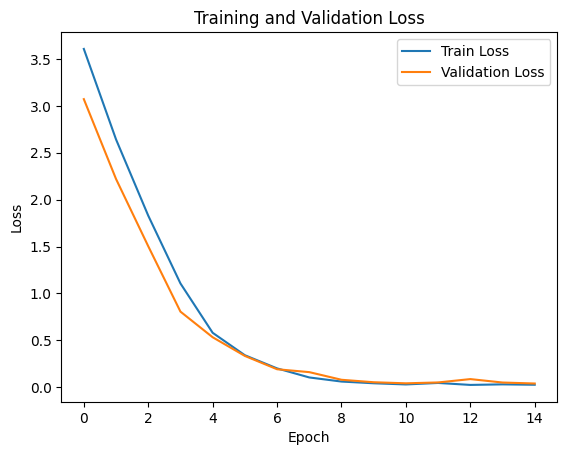

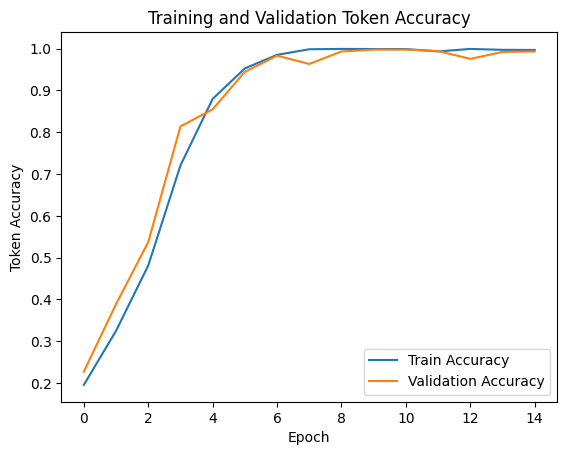

In [20]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.figure()
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Token Accuracy")
plt.title("Training and Validation Token Accuracy")
plt.legend()
plt.show()


# Part 4 — Autoregressive Inference

During training, we used teacher forcing.

During inference, the correct target sequence is **not available**.

So generation becomes:

```text
<SOS>
  ↓
predict token
  ↓
append token
  ↓
feed the whole generated prefix back
  ↓
predict next token
  ↓
...
  ↓
<EOS>
```

This is autoregressive decoding.


In [21]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_SOURCE_LEN + 2):
    model.eval()

    src = src.to(device)

    # Start every sequence with SOS.
    generated = torch.full(
        (src.size(0), 1),
        SOS_ID,
        dtype=torch.long,
        device=device
    )

    finished = torch.zeros(
        src.size(0),
        dtype=torch.bool,
        device=device
    )

    for _ in range(max_len):
        logits = model(src, generated)

        # Last time step predicts the next token.
        next_token = logits[:, -1, :].argmax(dim=-1)

        # Once EOS is generated, keep EOS.
        next_token = torch.where(
            finished,
            torch.full_like(next_token, EOS_ID),
            next_token
        )

        generated = torch.cat(
            [generated, next_token.unsqueeze(1)],
            dim=1
        )

        finished = finished | (next_token == EOS_ID)

        if finished.all():
            break

    return generated


In [22]:
def decode_target_sequence(sequence):
    tokens = sequence.tolist()

    result = []

    for token in tokens:
        if token == SOS_ID:
            continue
        if token == EOS_ID:
            break
        if token == PAD_ID:
            continue

        result.append(token)

    return result


# Test several validation examples.
for i in range(5):
    src, target = val_dataset[i]

    src_batch = src.unsqueeze(0)

    generated = greedy_decode(model, src_batch)

    print("Input    :", src.tolist())
    print("Expected :", target.tolist())
    print("Generated:", decode_target_sequence(generated[0]))
    print("-" * 50)


Input    : [6, 12]
Expected : [12, 6]
Generated: [12, 6]
--------------------------------------------------
Input    : [16, 11, 25, 16]
Expected : [16, 25, 11, 16]
Generated: [16, 25, 11, 16]
--------------------------------------------------
Input    : [28, 24]
Expected : [24, 28]
Generated: [24, 28]
--------------------------------------------------
Input    : [7, 28, 14, 20, 3]
Expected : [3, 20, 14, 28, 7]
Generated: [3, 20, 14, 28]
--------------------------------------------------
Input    : [23, 15, 12, 5]
Expected : [5, 12, 15, 23]
Generated: [5, 12, 15, 23]
--------------------------------------------------


## 12. Sequence-Level Evaluation

Token accuracy is useful, but a seq2seq model can have high token accuracy while still producing an incorrect sequence.

For this simple task, we can use **exact sequence match**:

$$[
SequenceAccuracy =
\frac{\#\ correct\ complete\ sequences}
{\#\ sequences}
]
$$

In [23]:
@torch.no_grad()
def sequence_accuracy(dataset):
    model.eval()

    correct = 0

    for i in range(len(dataset)):
        source, target = dataset[i]

        generated = greedy_decode(
            model,
            source.unsqueeze(0)
        )[0]

        prediction = decode_target_sequence(generated)

        if prediction == target.tolist():
            correct += 1

    return correct / len(dataset)


print("Validation sequence accuracy:",
      sequence_accuracy(val_dataset))


Validation sequence accuracy: 0.97


# Part 5 — Framework Comparison

Only after the manual implementation works should we compare it with PyTorch's built-in Transformer.

The purpose is **not** to replace our implementation.

It is to understand what a framework gives us:

| Manual implementation | PyTorch framework |
|---|---|
| We write attention ourselves | Optimized implementation |
| We handle masks ourselves | Framework APIs handle much of the plumbing |
| Easy to inspect every tensor | Easier to build production models |
| Excellent for learning | Better for practical development |

The manual implementation is for understanding.

Framework components are for productivity, optimization, and production-oriented work.


In [24]:
# Reference only — do NOT use this for the main model above.

pytorch_reference = nn.Transformer(
    d_model=d_model,
    nhead=num_heads,
    num_encoder_layers=num_encoder_layers,
    num_decoder_layers=num_decoder_layers,
    dim_feedforward=d_ff,
    batch_first=True
)

print(pytorch_reference)


Transformer(
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out